# Разведочный анализ данных (EDA)
Лабораторные анализы: основной набор документов и внешние изображения.

## 1. Загрузка данных и проверка структуры

In [13]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'data/metadata.csv').is_file() and (p / 'data/pages.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Не найдены data/metadata.csv и data/pages.csv. Сохрани CSV в year_project/data/ и открой ноутбук из year_project/notebooks/.')
DATA = ROOT / 'data'
metadata = pd.read_csv(DATA / 'metadata.csv', dtype={'document_id':'string', 'patient_id':'string'})
pages = pd.read_csv(DATA / 'pages.csv', dtype={'document_id':'string'})
external_file = DATA / 'external_metadata.csv'
if not external_file.exists():
    raise FileNotFoundError('Не найден data/external_metadata.csv: положи туда файл external_metadata(1).csv под этим именем.')
external = pd.read_csv(external_file, dtype={'image_id':'string', 'source_pdf':'string'})
for df in (metadata, pages, external):
    df.replace(r'^\s*$', pd.NA, regex=True, inplace=True)
expected = {
    'metadata': {'document_id','source_filename','patient_id','analysis_date','laboratory','analysis_type','total_pages'},
    'pages': {'document_id','page_number','total_pages','image_path','width','height'},
    'external': {'image_id','image_path','source_pdf','width','height','sha256','is_lab_report','analysis_type','laboratory','language','annotation_status','needs_review'}
}
for name, df in [('metadata',metadata),('pages',pages),('external',external)]:
    missing = expected[name] - set(df.columns)
    if missing: raise ValueError(f'В {name} отсутствуют столбцы: {sorted(missing)}')
print(f'Основные: {len(metadata)} документов / {len(pages)} страниц; внешняя выборка: {len(external)} изображений')

Основные: 35 документов / 69 страниц; внешняя выборка: 20 изображений


## 2. Общая статистика
Количество документов, страниц, пациентов, лабораторий и внешних изображений.

In [14]:
summary = pd.Series({
    'Документов в основном реестре': len(metadata),
    'Страниц в основном реестре': len(pages),
    'Пациентов (основной реестр)': metadata['patient_id'].nunique(),
    'Лабораторий': pd.concat([
        metadata['laboratory'],
        external['laboratory']
    ]).nunique(),
    'Внешних изображений в реестре': len(external),
}, name='Количество')

print(summary.to_string())

for name, df in [
    ('Основные документы', metadata),
    ('Основные страницы', pages),
    ('Внешние изображения', external)
]:
    if not df.empty:
        print(f'{name} — {df.shape[0]} строк, {df.shape[1]} столбцов')

Документов в основном реестре    35
Страниц в основном реестре       69
Пациентов (основной реестр)       3
Лабораторий                      13
Внешних изображений в реестре    20
Основные документы — 35 строк, 7 столбцов
Основные страницы — 69 строк, 6 столбцов
Внешние изображения — 20 строк, 20 столбцов


## 3. Распределения по категориям
Сравниваются типы анализов, лаборатории, языки и форматы. В основном наборе единица наблюдения — документ, во внешнем — изображение; суммарные количества нужно интерпретировать с учётом этого различия.

,Количество
patient_id,
P001,16
P002,12
P003,7


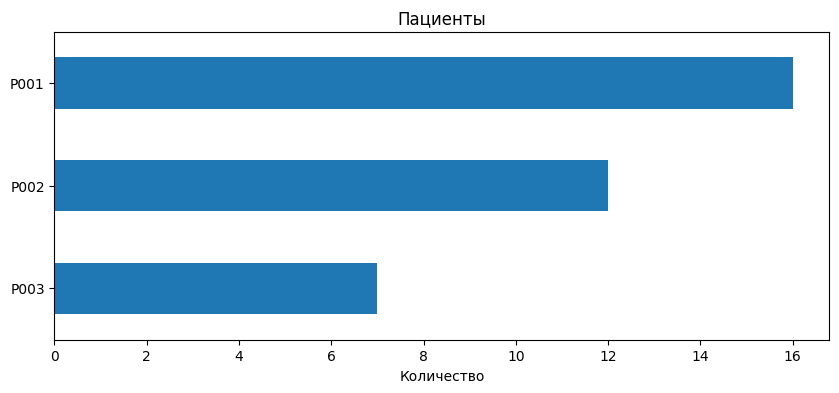

,Количество
analysis_type,
CBC,35
complete_blood_count,12
serology,3
biochemistry,1
hormonal_assay,1
complete_blood_count_and_biochemistry,1
immunology,1
biochemistry_and_serology,1


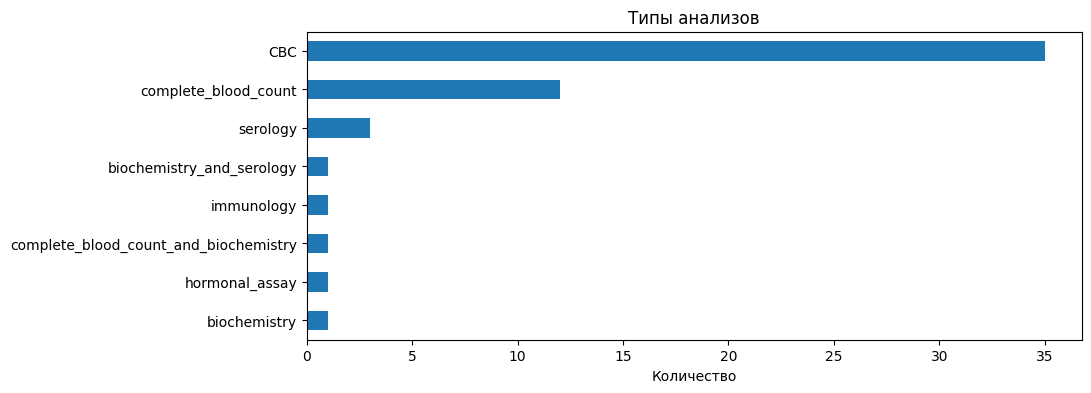

,Количество
laboratory,
Policlinika,28
Medsi,7
Swastik Hospital,6
Sanjay Multi Speciality Hospital,4
Shree Diagnostic Clinical Laboratory,2
SRS Multi Speciality Hospital,1
Maharishi Markandeshwar College of Medical Sciences and Research,1
EVYA Multi Speciality Hospitals,1
Apollo Hospitals Nashik,1


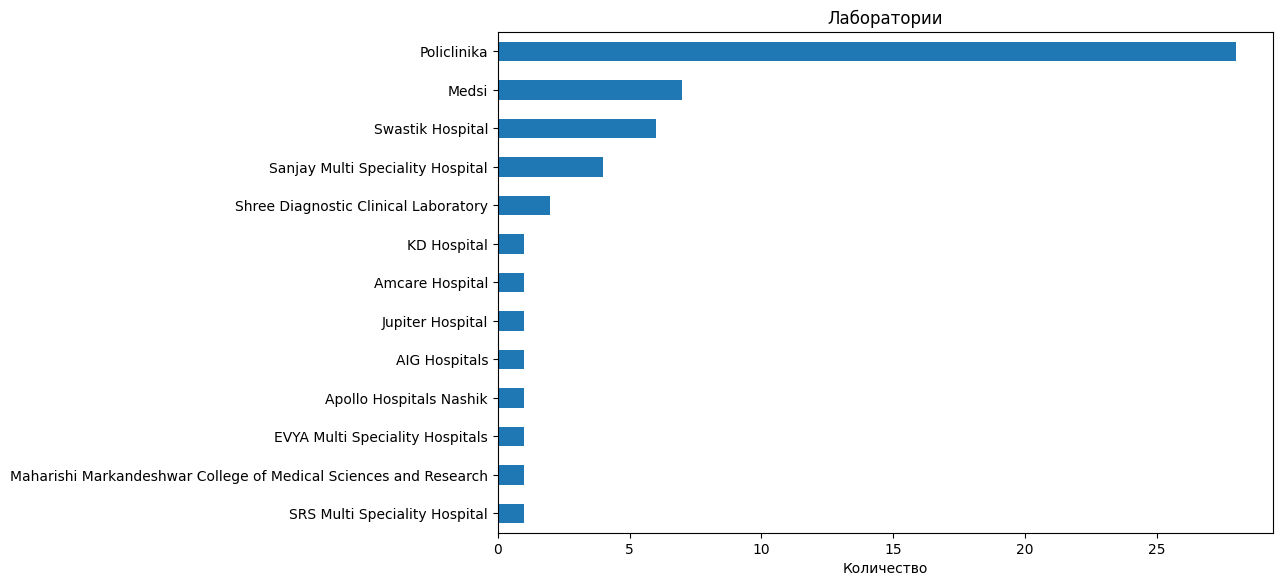

,Количество
language,
Русский,35
en,20


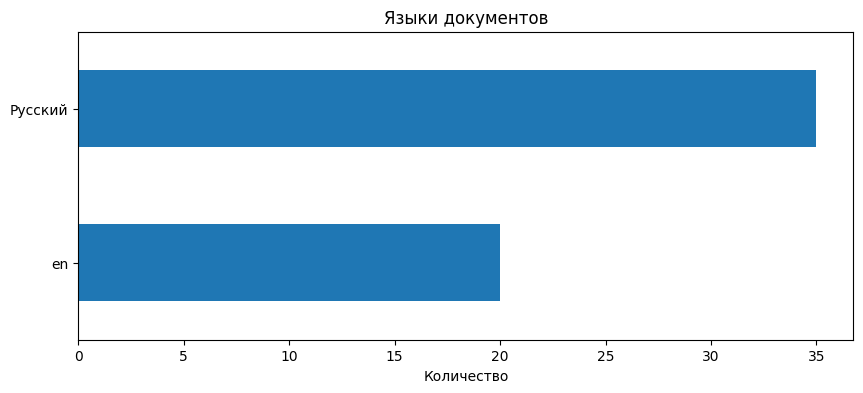

,Количество
format,
pdf,35
PNG,20


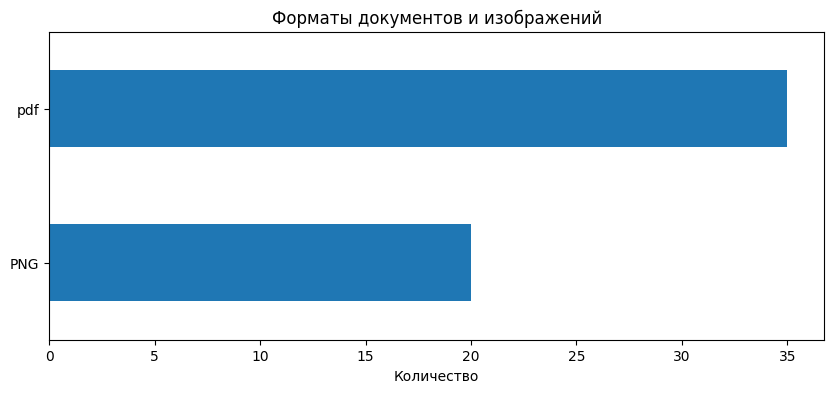

In [15]:
def category_plot(df, column, title):
    if df.empty or column not in df:
        return

    counts = df[column].fillna('Не размечено').astype(str).value_counts()

    # Таблица
    display(counts.rename('Количество').to_frame())

    # Горизонтальный график
    ax = counts.sort_values().plot.barh(
        figsize=(10, max(4, len(counts) * 0.5)),
        title=title
    )
    ax.set_xlabel('Количество')
    ax.set_ylabel('')
    plt.show()

combined = pd.concat([
    metadata[['laboratory', 'analysis_type']].assign(language='Русский'),
    external[['laboratory', 'analysis_type', 'language']]
], ignore_index=True)

metadata['format'] = metadata['source_filename'].apply(
    lambda x: Path(str(x)).suffix.lower().replace('.', '') if pd.notna(x) else pd.NA
)

combined_formats = pd.concat([
    metadata[['format']],
    external[['format']]
], ignore_index=True)

category_plot(metadata, 'patient_id', 'Пациенты')
category_plot(combined, 'analysis_type', 'Типы анализов')
category_plot(combined, 'laboratory', 'Лаборатории')
category_plot(combined, 'language', 'Языки документов')
category_plot(combined_formats, 'format', 'Форматы документов и изображений')

## 4. Характеристики и доступность изображений


Основные страницы
Проверка изображений


,Количество
Показатель,
Всего записей об изображениях,69
Файлов найдено в текущей среде,69
Файлов успешно прочитано,69
Файлов с ошибкой чтения,0
Файлов не найдено в текущей среде,0
Разрешение взято из CSV,0
Размер файла взят из CSV,0


Характеристики изображений


,Ширина (пикс.),Высота (пикс.),Размер файла (КБ),Соотношение сторон,Мегапиксели
Количество,69.00,69.00,69.00,69.00,69.00
Среднее,3302.38,2871.57,761.86,1.22,9.81
Стандартное отклонение,708.07,1088.12,828.78,0.32,9.19
Минимум,2480.00,2480.00,169.60,0.71,8.70
25-й процентиль,2482.00,2480.00,504.00,0.71,8.70
Медиана,3509.00,2480.00,737.10,1.41,8.70
75-й процентиль,3509.00,3509.00,838.40,1.41,8.70
Максимум,7754.00,10966.00,7276.40,1.41,85.03


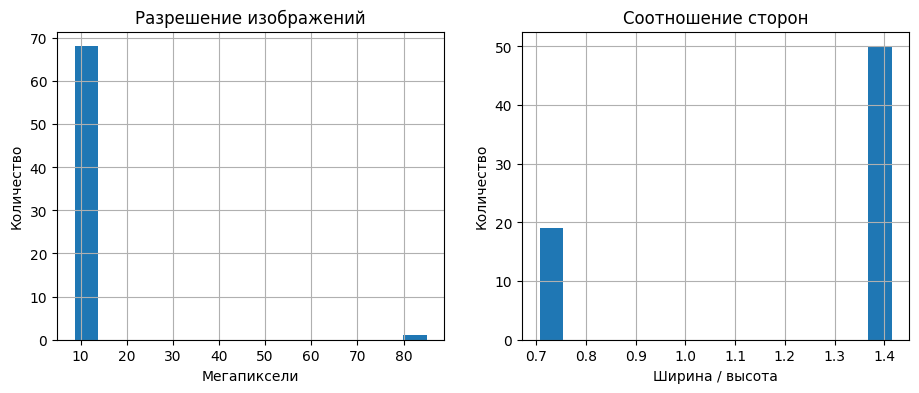


Внешние изображения
Проверка изображений


,Количество
Показатель,
Всего записей об изображениях,20
Файлов найдено в текущей среде,10
Файлов успешно прочитано,10
Файлов с ошибкой чтения,0
Файлов не найдено в текущей среде,10
Разрешение взято из CSV,10
Размер файла взят из CSV,10


Характеристики изображений


,Ширина (пикс.),Высота (пикс.),Размер файла (КБ),Соотношение сторон,Мегапиксели
Количество,20.00,20.00,20.00,20.00,20.00
Среднее,1645.90,2326.85,2373.17,0.71,3.83
Стандартное отклонение,11.83,23.38,1186.88,0.01,0.06
Минимум,1614.00,2275.00,362.90,0.70,3.68
25-й процентиль,1645.00,2322.25,1791.38,0.71,3.82
Медиана,1649.50,2339.00,2117.90,0.71,3.86
75-й процентиль,1653.00,2339.00,2512.55,0.71,3.87
Максимум,1656.00,2348.00,5721.20,0.72,3.87


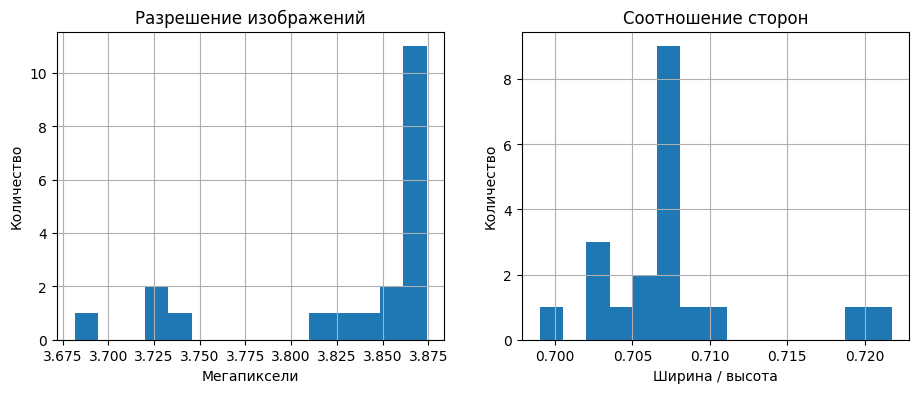

In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display


# 1. Поиск изображений
def resolve_image_path(value):
    if pd.isna(value):
        return None

    p = Path(str(value))
    candidates = [p] if p.is_absolute() else [ROOT / p, DATA / p]

    return next(
        (candidate for candidate in candidates if candidate.is_file()),
        None
    )

# 2. Проверка изображений и получение характеристик
def inspect_images(df):
    results = []

    for _, row in df.iterrows():
        path = resolve_image_path(row['image_path'])

        width = pd.to_numeric(row.get('width'), errors='coerce')
        height = pd.to_numeric(row.get('height'), errors='coerce')
        file_size = pd.to_numeric(row.get('file_size_kb'), errors='coerce')

        item = {
            'image_path': row['image_path'],
            'exists': path is not None,
            'valid': pd.NA,
            'width': width,
            'height': height,
            'file_size_kb': file_size,
            'size_source': (
                'CSV' if pd.notna(width) and pd.notna(height)
                else 'Нет данных'
            ),
            'file_size_source': (
                'CSV' if pd.notna(file_size)
                else 'Нет данных'
            )
        }

        if path is not None:
            try:
                item['file_size_kb'] = round(
                    path.stat().st_size / 1024, 1
                )
                item['file_size_source'] = 'Файл'

                with Image.open(path) as im:
                    im.verify()

                with Image.open(path) as im:
                    im.load()
                    item['width'] = im.width
                    item['height'] = im.height

                item['valid'] = True
                item['size_source'] = 'Файл'

            except (OSError, ValueError, Image.DecompressionBombError):
                item['valid'] = False

        results.append(item)

    result = pd.DataFrame(results)

    # Преобразование числовых значений
    for col in ['width', 'height', 'file_size_kb']:
        result[col] = pd.to_numeric(
            result[col], errors='coerce'
        )

    # Расчёт характеристик изображений
    positive_dimensions = (
        (result['width'] > 0) &
        (result['height'] > 0)
    )

    result['aspect_ratio'] = (
        result['width'] / result['height']
    ).where(positive_dimensions)

    result['megapixels'] = (
        result['width'] * result['height'] / 1e6
    ).where(positive_dimensions)

    return result


# 3. Проверка двух датасетов
local = inspect_images(pages)
external_checked = inspect_images(external)


# 4. Анализ каждого датасета отдельно
for name, df in [
    ('Основные страницы', local),
    ('Внешние изображения', external_checked)
]:
    print(f'\n{name}')

    # Таблица проверки изображений
    check_summary = pd.DataFrame({
        'Показатель': [
            'Всего записей об изображениях',
            'Файлов найдено в текущей среде',
            'Файлов успешно прочитано',
            'Файлов с ошибкой чтения',
            'Файлов не найдено в текущей среде',
            'Разрешение взято из CSV',
            'Размер файла взят из CSV'
        ],
        'Количество': [
            len(df),
            int(df['exists'].sum()),
            int(df['valid'].eq(True).sum()),
            int(df['valid'].eq(False).sum()),
            int((~df['exists']).sum()),
            int(df['size_source'].eq('CSV').sum()),
            int(df['file_size_source'].eq('CSV').sum())
        ]
    })

    print('Проверка изображений')
    display(check_summary.set_index('Показатель'))

    # 5. Статистика характеристик изображений
    cols = [
        'width',
        'height',
        'file_size_kb',
        'aspect_ratio',
        'megapixels'
    ]

    stats = df[cols].describe().round(2)

    # Названия столбцов на русском языке
    stats.columns = [
        'Ширина (пикс.)',
        'Высота (пикс.)',
        'Размер файла (КБ)',
        'Соотношение сторон',
        'Мегапиксели'
    ]

    # Статистические показатели на русском языке
    stats = stats.rename(index={
        'count': 'Количество',
        'mean': 'Среднее',
        'std': 'Стандартное отклонение',
        'min': 'Минимум',
        '25%': '25-й процентиль',
        '50%': 'Медиана',
        '75%': '75-й процентиль',
        'max': 'Максимум'
    })

    print('Характеристики изображений')
    display(stats)

    # 6. Графики характеристик
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    for axis, column, title, xlabel in [
        (
            ax[0],
            'megapixels',
            'Разрешение изображений',
            'Мегапиксели'
        ),
        (
            ax[1],
            'aspect_ratio',
            'Соотношение сторон',
            'Ширина / высота'
        )
    ]:
        values = df[column].dropna()

        if values.empty:
            axis.text(
                0.5, 0.5,
                'Нет данных',
                ha='center',
                va='center',
                transform=axis.transAxes
            )
        else:
            values.hist(ax=axis, bins=15)

        axis.set_title(title)
        axis.set_xlabel(xlabel)
        axis.set_ylabel('Количество')

    plt.show()

## 5. Состояние разметки

На текущем этапе проекта эталонная разметка результатов лабораторных анализов отсутствует. Имеющиеся таблицы содержат метаданные документов и изображений, включая информацию о типах анализов и лабораториях, но не содержат размеченных медицинских показателей и их значений. Создание такой разметки в рамках текущего этапа не планируется. Основное внимание уделяется исследованию собранных данных, оценке их качества и пригодности для дальнейшего автоматического распознавания.

## 6. ML-задача и план проверки

**Что должна делать система.** Получать изображение лабораторного анализа и извлекать дату и структурированные показатели: название, значение, единицу измерения и референсный интервал. Для многостраничных документов результаты нужно объединять по документу.

**Что уже есть в данных.** В основном реестре — **35 документов (69 страниц)**, **3 пациента**, **2 лаборатории**; у всех документов тип `CBC` (общий анализ крови). Во внешней размеченной подвыборке — **20 изображений** из **15 исходных PDF**, **11 лабораторий** и несколько типов исследований. Это метаданные и классификация страниц, а не эталонные значения медицинских показателей. 

**Что потребуется разметить.** Для выбранных страниц подготовить эталонные результаты: идентификатор документа/страницы, название показателя, значение, единицу и референсный интервал, при наличии дату анализа. Координаты текста необязательны для оценки уже извлечённых структурированных результатов.



## 7. Итоги EDA

Сводка рассчитывается по всем записям трёх CSV. **Количество записей, сохранённая валидность и фактическая доступность файлов — разные показатели.** Если часть PNG отсутствует в текущей среде, это не исключает соответствующие записи из анализа характеристик, сохранённых в CSV.

In [17]:
# Итоговые показатели по всем строкам текущих CSV
required_classification = ['is_lab_report', 'analysis_type', 'laboratory', 'language']
missing_classification = int(external[required_classification].isna().any(axis=1).sum())
external_metadata_valid = int(
    external['is_valid'].astype('string').str.strip().str.lower().eq('true').sum()
) if 'is_valid' in external.columns else pd.NA

results = pd.Series({
    'Основных документов': len(metadata),
    'Основных страниц': len(pages),
    'Пациентов в основном наборе': metadata['patient_id'].nunique(),
    'Лабораторий в основном наборе': metadata['laboratory'].nunique(),
    'Внешних изображений (все записи CSV)': len(external),
    'Исходных PDF во внешнем наборе': external['source_pdf'].nunique(),
    'Внешних изображений с сохранённым размером файла': int(
        external_checked['file_size_kb'].notna().sum()
    ),
    'Внешних файлов найдено в текущей среде': int(external_checked['exists'].sum()),
    'Внешних файлов не найдено в текущей среде': int((~external_checked['exists']).sum()),
}, name='Количество')

print('Итоговая сводка EDA')
display(results.to_frame())


Итоговая сводка EDA


,Количество
Основных документов,35
Основных страниц,69
Пациентов в основном наборе,3
Лабораторий в основном наборе,2
Внешних изображений (все записи CSV),20
Исходных PDF во внешнем наборе,15
Внешних изображений с сохранённым размером файла,20
Внешних файлов найдено в текущей среде,10
Внешних файлов не найдено в текущей среде,10


### Выводы и следующие шаги

- **Основной набор:** 35 документов, 69 страниц, 3 пациента, 2 лаборатории; все документы отмечены типом `CBC` (общий анализ крови).
- **Внешний набор:** 20 изображений. Они соответствуют 15 исходным PDF и 11 лабораториям.
- **Доступность файлов — отдельная проверка:** если при запуске обнаружены не все PNG, анализ всё равно учитывает все 20 строк CSV, включая сохранённые размеры в пикселях и килобайтах. Отсутствующий по пути файл не следует объявлять повреждённым. 
- **Следующий этап:** подготовить эталонную разметку показателей на страницах из разных лабораторий, затем сравнить PaddleOCR с правилами извлечения и Qwen2.5-VL на одинаковых примерах. Возможные различия качества между русскоязычными и англоязычными бланками проверить экспериментально.

**Ограничение EDA:** точность OCR и извлечения медицинских значений пока не измерена.